In [1]:
using DifferentialEquations, Plots
using DifferentialEquations.EnsembleAnalysis
using StatsBase, DataFrames

In [2]:
# DE setup
function μ_SDE(du,u,p,t)
  du .= p.μ
end

function σ_SDE(du,u,p,t)
  du .= p.σ
end

σ_SDE (generic function with 1 method)

In [3]:
# Callback setup
T = 10.;

function save_func(u, t, integrator) 
    if length(integrator.p.moments) == 0 
        g = 0.
    else
        g = mean(u) - integrator.p.moments[end][2]
    end            
    moments = [minimum(u), mean(u), maximum(u), g]
    push!(integrator.p.moments, moments) 
end 

save_func (generic function with 1 method)

In [5]:
p = (μ = 0.01, σ = 0.1, N = 3, moments = Array{Array{Float64, 1}, 1}());
x_iv = rand(p.N)
prob = SDEProblem(μ_SDE, σ_SDE, x_iv ,(0.0, T), p);
saveat = 0:0.1:T

cb = FunctionCallingCallback(save_func;
                 funcat=saveat,
                 func_everystep=false,
                 func_start = true,
                 tdir=1);

In [6]:
# Ensemble setup 
function output_func(sol, i)
    resize!(sol.t, 0)
    resize!(sol.u, 0)
    append!(sol.t, saveat) # or something like that... need the `t` values we used for the moments
    append!(sol.u, sol.prob.p.moments)
    return (sol, false)
end

output_func (generic function with 1 method)

In [8]:
ensemble_prob = EnsembleProblem(prob, output_func = output_func)

EnsembleProblem with problem SDEProblem

In [9]:
sim = solve(ensemble_prob,Tsit5(), EnsembleSerial(), trajectories = 2, callback = cb);

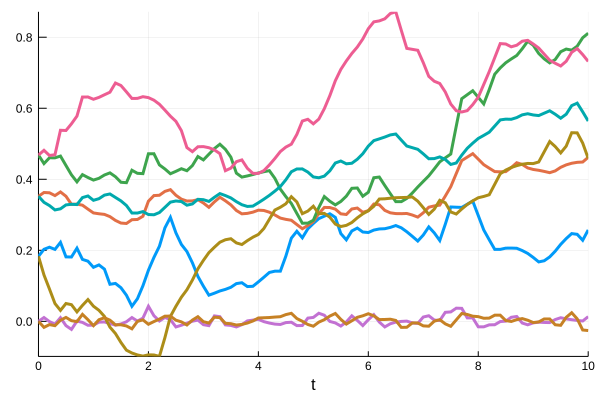

In [10]:
plot(sim)

In [12]:
sim.u[1]

retcode: Success
Interpolation: 1st order linear
t: 101-element Array{Float64,1}:
  0.0
  0.1
  0.2
  0.3
  0.4
  0.5
  0.6
  0.7
  0.8
  0.9
  1.0
  1.1
  1.2
  ⋮  
  8.9
  9.0
  9.1
  9.2
  9.3
  9.4
  9.5
  9.6
  9.7
  9.8
  9.9
 10.0
u: 101-element Array{Array{Float64,1},1}:
 [0.18302, 0.352083, 0.468184, 0.0]          
 [0.202803, 0.362734, 0.44421, 0.0106514]    
 [0.208725, 0.361932, 0.460514, -0.000802148]
 [0.202573, 0.354065, 0.460404, -0.00786709] 
 [0.222341, 0.364321, 0.46533, 0.0102557]    
 [0.181507, 0.352192, 0.4388, -0.0121291]    
 [0.18113, 0.329438, 0.412536, -0.0227536]   
 [0.205981, 0.330087, 0.392728, 0.000649368] 
 [0.17438, 0.327057, 0.413056, -0.00303048]  
 [0.16938, 0.315949, 0.404945, -0.0111081]   
 [0.152094, 0.305231, 0.397752, -0.0107172]  
 [0.158858, 0.302877, 0.402653, -0.00235477] 
 [0.14697, 0.301122, 0.412017, -0.00175512]  
 ⋮                                           
 [0.191236, 0.431964, 0.788749, -0.00978823] 
 [0.179889, 0.427636, 0.777487

In [29]:
summ = EnsembleSummary(sim, quantiles=[0.05, 0.95])

EnsembleSolution Solution of length 101 with uType:
Float64

In [30]:
propertynames(summ)

(:t, :u, :v, :qlow, :qhigh, :num_monte, :elapsedTime, :converged)

In [31]:
summ.t == saveat

true

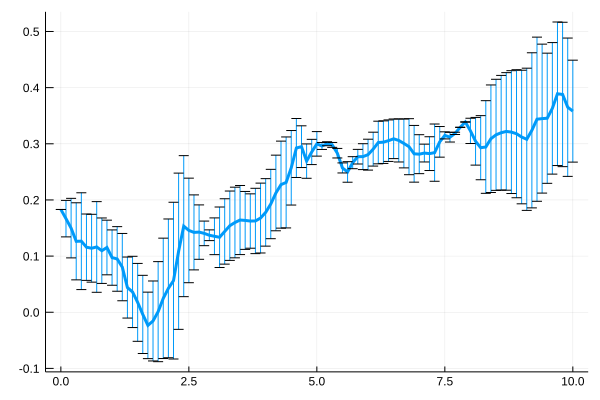

In [35]:
plot(summ, idxs=[1], error_style = :bars)

In [38]:
] st

Project KnowledgeDiffusionSimulations v0.1.0
    Status `~/Research/packages/KnowledgeDiffusionSimulations.jl/Project.toml`
  (no changes since last commit)
